<a href="https://colab.research.google.com/github/alirezakiann/cx-radar/blob/main/01_data_snappfood.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 - دریافت دیتاست اسنپ‌فود (بدون Google Drive)
همه‌چیز روی خود Colab اجرا می‌شه. داده هر بار از Kaggle دوباره دانلود می‌شه (چند ثانیه) و کد توی GitHub نگه‌داری می‌شه.

## قدم ۱: ذخیره‌ی توکن Kaggle توی Colab Secrets
توکنی که Kaggle بهت داده رو **توی نوت‌بوک ننویس**. به‌جاش:
1. توی Colab سمت چپ روی آیکون **کلید 🔑 (Secrets)** بزن.
2. `Add new secret` بزن.
3. اسم: `KAGGLE_API_TOKEN` (دقیقاً همین)
4. مقدار: توکنی که از Kaggle گرفتی (چیزی شبیه `KGAT_...`)
5. کلید **Notebook access** رو روشن کن.

اینطوری توکن داخل فایل نوت‌بوک نمی‌مونه و موقع آپلود به GitHub لو نمی‌ره.

## قدم ۲: نصب و ورود

In [3]:
!pip install -q kagglehub hazm pyarrow
import os
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
print('توکن خوانده شد:', bool(os.environ['KAGGLE_API_TOKEN']))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
توکن خوانده شد: True


## قدم ۳: دانلود دیتاست
اگه خطای دسترسی گرفتی، صفحه‌ی دیتاست رو توی Kaggle یک بار باز کن و شرایطش رو قبول کن.

In [4]:
import kagglehub
path = kagglehub.dataset_download('soheiltehranipour/snappfood-persian-sentiment-analysis')
print('مسیر:', path)
!ls -la "{path}"

Using Colab cache for faster access to the 'snappfood-persian-sentiment-analysis' dataset.
مسیر: /kaggle/input/snappfood-persian-sentiment-analysis
total 11632
drwxr-sr-x 2 ubuntu ubuntu        0 Nov 24 13:31  .
drwxr-xr-x 3 root   root       4096 Nov 24 17:20  ..
-rw-r--r-- 1 ubuntu ubuntu 11905281 Nov 24 13:30 'Snappfood - Sentiment Analysis.csv'


## قدم ۴: خوندن فایل‌ها
ساختار دقیق فایل‌ها رو از قبل ندیده‌م. کد خودش جداکننده و ستون‌ها رو تشخیص می‌ده.

In [5]:
import glob, pandas as pd
csvs = glob.glob(f'{path}/**/*.csv', recursive=True)
print(csvs)

dfs = []
for p in csvs:
    d = pd.read_csv(p, sep=None, engine='python', encoding='utf-8')
    d['source_file'] = p.split('/')[-1]
    print(p.split('/')[-1], d.shape, list(d.columns))
    dfs.append(d)
df = pd.concat(dfs, ignore_index=True)
df.head()

['/kaggle/input/snappfood-persian-sentiment-analysis/Snappfood - Sentiment Analysis.csv']
Snappfood - Sentiment Analysis.csv (70000, 5) ['Unnamed: 0', 'comment', 'label', 'label_id', 'source_file']


,Unnamed: 0,comment,label,label_id,source_file
0,NaN,واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح,SAD,1.0,Snappfood - Sentiment Analysis.csv
1,NaN,قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از مو...,HAPPY,0.0,Snappfood - Sentiment Analysis.csv
2,NaN,قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط...,SAD,1.0,Snappfood - Sentiment Analysis.csv
3,NaN,عالللی بود همه چه درست و به اندازه و کیفیت خوب...,HAPPY,0.0,Snappfood - Sentiment Analysis.csv
4,NaN,شیرینی وانیلی فقط یک مدل بود.,HAPPY,0.0,Snappfood - Sentiment Analysis.csv


## قدم ۵: شناخت اولیه
اگه اسم ستون متن `comment` نیست، `TEXT_COL` رو عوض کن.

In [6]:
TEXT_COL = 'comment'
LABEL_COL = 'label'

print('تعداد ردیف‌ها :', len(df))
print('\nمقادیر خالی:'); print(df[[TEXT_COL, LABEL_COL]].isna().sum())
print('\nتکراری‌ها (بر اساس متن):', df.duplicated(subset=[TEXT_COL]).sum())
print('\nتوزیع برچسب‌ها:'); print(df[LABEL_COL].value_counts())

تعداد ردیف‌ها : 70000

مقادیر خالی:
comment    0
label      0
dtype: int64

تکراری‌ها (بر اساس متن): 518

توزیع برچسب‌ها:
label
HAPPY    34916
SAD      34564
1          436
0           84
Name: count, dtype: int64


count    70000.000000
mean        18.504029
std         15.807516
min          1.000000
25%          8.000000
50%         14.000000
75%         23.000000
max        361.000000
Name: n_words, dtype: float64


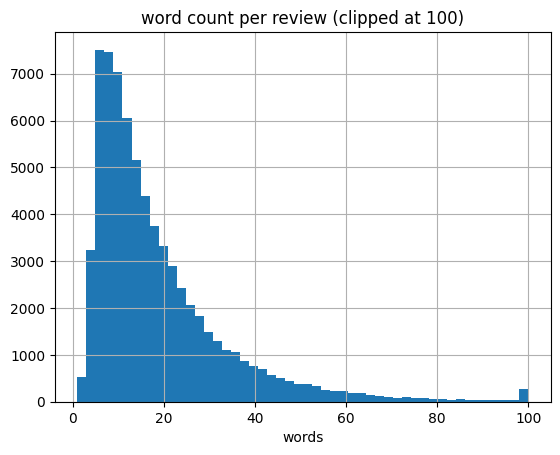

In [7]:
df['n_words'] = df[TEXT_COL].astype(str).str.split().str.len()
print(df['n_words'].describe())

import matplotlib.pyplot as plt
df['n_words'].clip(upper=100).hist(bins=50)
plt.title('word count per review (clipped at 100)'); plt.xlabel('words'); plt.show()

## قدم ۶: چند نمونه‌ی واقعی بخون
به چشم خودت بخون. دیدن داده مهم‌ترین کار تحلیل‌گره.

In [8]:
pd.set_option('display.max_colwidth', 200)
for lab in df[LABEL_COL].dropna().unique():
    print('=====', lab)
    print(df[df[LABEL_COL] == lab][TEXT_COL].sample(5, random_state=1).to_string(index=False))

===== SAD
                                                                                                     تو قیمتا زده بود پیتزا ۴ فصل و ۳۶۷۰۰ با ۲ تا نوشابه که میشه اونم ۵ میشه ۴۱۷۰۰ ولی از من ۴۸۷۰۰ گرفتن
                                                                                                                                                      اصلا" راضى نبودم ١ساعت و نیم طول کشید به دستم برسه
                            اصلا راضی نیستم با این که اولین بار نبود که به سیب سفارش میدادم اما اخرین بار خواهد بود. متاسفانه سفارشم با دو ساعت تاخیر به دستم رسید غذا هم کیفیت همیشگی را نداشت متاسفانه
                                                                                                               مرغ تریاکی اصلا مزه سس تریاکی نمیداد. ولی یه سس سفید رنگ داشت که مزه مایونز با روغن میداد
متاسفانه علارقم زحمت زیادی که برای پخت پیتزا کشیده شده بودند. همونطور که یک نفر دیگه هم در مورد پیتزا الفردو گفته بودند متاسفانه مرغ‌ها با حجم زیاد رو پیتزا ریخته شده ولی ظاهرا این مرغ ف

## قدم ۷: ذخیره‌ی خام روی دیسک موقت Colab
این پوشه با بسته شدن Colab پاک می‌شه و اشکالی نداره، چون با اجرای دوباره‌ی نوت‌بوک ساخته می‌شه. بعداً داده‌ی پاک‌شده‌ی کوچک رو توی GitHub می‌ذاریم.

In [9]:
os.makedirs('/content/cx-radar/data/raw', exist_ok=True)
df.to_parquet('/content/cx-radar/data/raw/snappfood_raw.parquet', index=False)
print('ذخیره شد، حجم:', os.path.getsize('/content/cx-radar/data/raw/snappfood_raw.parquet')//1024, 'KB')

ذخیره شد، حجم: 5554 KB


## ✍️ تمرین (جواب‌ها رو برای من بفرست)
۱. چند ردیف داریم و چند تا تکراریه؟
۲. توزیع برچسب‌ها متعادله؟
۳. میانگین و بیشترین طول نظرها چقدره؟
۴. توی ۱۰ نمونه‌ای که خوندی، چه چیزهای «کثیفی» دیدی؟ (ایموجی، فینگلیش، غلط املایی، ...)

In [10]:
bad = df[df['label'].astype(str).isin(['0', '1'])]
print('تعداد ردیف خراب:', len(bad))
print(bad['source_file'].value_counts())
print(list(df.columns))
bad.head(10)

تعداد ردیف خراب: 520
source_file
Snappfood - Sentiment Analysis.csv    520
Name: count, dtype: int64
['Unnamed: 0', 'comment', 'label', 'label_id', 'source_file', 'n_words']


,Unnamed: 0,comment,label,label_id,source_file,n_words
21,هزار پول ساندویچ شد، ولی بیشترش قارچ بود,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
89,ساعت و نیم تاخیر برای ارسال یک عدد ساندویچ! و تحویل ساندویخ سرد و خیس!,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
161,تومن پیتزا خریدم سس نداده بود بدون سس خوردم,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
180,تا شونه تخم مرغ را نیاوردید,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
243,- سریع رسید ۲- بسته بندی مناسب بود ۳- دور چین خوراک کباب لقمه ضعیف بود، برای سه پرس غذا فقط یک برش پیاز، یک بسته سبزی و دو عدد فلفل کوچیک و یه اسلایس کوچک ته دیگ … همین!!,HAPPY,0,NaN,Snappfood - Sentiment Analysis.csv,1
287,تا سنگگ یک ساعت و بیست دقیقه باید طول بکشه؟!!! غذا تموم شد نیم ساعت بعد سنگگ‌ رسید,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
288,عدد بستنی داخل سفارشم بود اما ارسال نشد حتی داخل فاکتور هم تیک نخورده اگر نداشتن باید اطلاع میدادن ممنون,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
415,ساعت ۳۰ دقیقه طول کشید تا آورد اصلا وقت مردم مهم نیست براتون,HAPPY,0,NaN,Snappfood - Sentiment Analysis.csv,1
480,ساعت طول کشید تا برسه.. ‌ جلو مهمونا آبروم رفت,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1
507,تیکه فیله اندازه سه بند انگشت. واقعات جالب بود. مگه میشه آخه. من از همه رستورانهای محدوده خرید کردم. ولی امروز شاخ درآوردم. کیفیت خوب بود ولی واقعا حجم غذا خیلی کم بود,SAD,1,NaN,Snappfood - Sentiment Analysis.csv,1


In [11]:
df_clean = df[df['label'].isin(['HAPPY', 'SAD'])].copy()
print('بعد از حذف ردیف‌های خراب:', len(df_clean))

# 1 یعنی منفی (SAD)، چون هدف ما پیدا کردن شکایت‌هاست
df_clean['is_negative'] = (df_clean['label'] == 'SAD').astype(int)

بعد از حذف ردیف‌های خراب: 69480


In [12]:
import re
from hazm import Normalizer

normalizer = Normalizer()
digit_map = str.maketrans('۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩', '01234567890123456789')

def clean_text(t):
    t = str(t)
    t = t.replace('ي', 'ی').replace('ى', 'ی').replace('ك', 'ک')   # حروف عربی
    t = normalizer.normalize(t)                                    # فاصله، کشیده، ...
    t = t.translate(digit_map)                                     # همه‌ی رقم‌ها انگلیسی
    t = re.sub(r'https?://\S+', ' ', t)                            # لینک
    t = re.sub(r'([^\W\d_])\1{2,}', r'\1\1', t)                    # خیلییییی → خیلیی
    t = re.sub(r'(\d)([^\W\d_])', r'\1 \2', t)                     # 1ساعت → 1 ساعت
    t = re.sub(r'([^\W\d_])(\d)', r'\1 \2', t)                     # پیتزا4 → پیتزا 4
    t = re.sub(r'\s+', ' ', t).strip()
    return t

df_clean['text'] = df_clean['comment'].map(clean_text)

for i in df_clean.sample(5, random_state=3).index:
    print('قبل :', df_clean.loc[i, 'comment'])
    print('بعد :', df_clean.loc[i, 'text'])
    print()

قبل : خیلی مزخرف بود سالاد شیرازی که خیار نداشت تو یه کیسه‌ای پیچونده بودن که چرب بود کباب ش هم لاستیک متاسفم
بعد : خیلی مزخرف بود سالاد شیرازی که خیار نداشت تو یه کیسه‌ای پیچونده بودن که چرب بود کباب‌ش هم لاستیک متاسفم

قبل : در کل حجم و طعم خوبی داشت اما خیلی شور بود
بعد : در کل حجم و طعم خوبی داشت اما خیلی شور بود

قبل : متاسفانه غذا بسیار بی کیفیت (چرب و غرق در روغن فراوان و آبکی و رقیق) بود. امیدوارم نسبت به بالابردن کیفیت تجدید نظر شود.
بعد : متاسفانه غذا بسیار بی‌کیفیت (چرب و غرق در روغن فراوان و آبکی و رقیق) بود. امیدوارم نسبت به بالابردن کیفیت تجدید نظر شود.

قبل : سپاس. از شما مامان و بابام دوست داشتن واین رضایت ارزشمند بود.
بعد : سپاس. از شما مامان و بابام دوست داشتن واین رضایت ارزشمند بود.

قبل : پیتزا بسیار با کیفیت و خوشمزه در بسته بندی زیبا
بعد : پیتزا بسیار با کیفیت و خوشمزه در بسته بندی زیبا



In [13]:
df_clean = df_clean[df_clean['text'].str.len() > 0]

print('تکراری واقعی:', df_clean.duplicated('text').sum())

# یک متن که یک بار HAPPY و یک بار SAD خورده
conf = df_clean.groupby('text')['is_negative'].nunique()
conf = conf[conf > 1]
print('متن یکسان با برچسب متناقض:', len(conf))
print(conf.index[:5].tolist())

تکراری واقعی: 55
متن یکسان با برچسب متناقض: 4
['خوشمزه بود ولی حجمش خیلی کم بود', 'سالاد کلم خیلی کوچیک بود', 'شیرینی تازه نبود اصلا', 'مرغ بوی زخم می\u200cداد']


In [14]:
df_clean = df_clean[~df_clean['text'].isin(conf.index)]
df_clean = df_clean.drop_duplicates('text')
df_clean['n_words'] = df_clean['text'].str.split().str.len()

print('ردیف نهایی:', len(df_clean))
print(df_clean['is_negative'].value_counts(normalize=True).round(3))
print('نظرهای ۲ کلمه‌ای یا کمتر:', (df_clean['n_words'] <= 2).sum())

os.makedirs('/content/cx-radar/data/interim', exist_ok=True)
df_clean[['text', 'is_negative', 'n_words']].to_parquet(
    '/content/cx-radar/data/interim/snappfood_clean.parquet', index=False)

ردیف نهایی: 69421
is_negative
0    0.502
1    0.498
Name: proportion, dtype: float64
نظرهای ۲ کلمه‌ای یا کمتر: 2


In [15]:
df_clean[df_clean['is_negative'] == 0]['text'].sample(20, random_state=7).to_list()

['عالی بود، مرسی، خیلی هم زود تحویل دادن',
 'زمان تحویل عالی بود غذا تازه و گرم بود مواد اولیه با کیفیت بود فقط مرغ پاپ کورنی می\u200cتونست بهتر باشه',
 'کیفیت غذا خوب بود ولی نان، مانده بود',
 'غذای فوق\u200cالعاده بسته بندی عالی و دیزاین خیلی خوب میشه یه رستوران درجه یک مثل شاهو',
 'پک عالی نان سنگک و سبزی تازه ماست خیار عالی کشک بادمجان همراه گردو خوشمزه بود پیک خوش\u200cبرخورد ممنون از اسنپ فود',
 'همیشه خوب بود وقتی چیزی رو نداشتین تماس می\u200cگرفتین می\u200cپرسیدین که جایگزینش کنیم یا نه، وقتی یه چیزی رو سفارش دادم یعنی همون رو میخوام، اگه ندارین نیاز نیست تصمیم بگیب',
 'خیلی خوب بود با تشکر از زحمات شما',
 'ساندویچ هم خوشمزه بود و هم حجمش مناسب بود از همه جالب\u200cتر این\u200cکه توی کمتر از 15 دقیقه به دستم رسید',
 'جوجه\u200cکباب خیلی خوشمزه و ترد بود و اصلا خشک یا سوخته نبود، برنج هم به خوبی دم کشیده بود و تهدیگ مناسبی داشت فقط حجم برنج می\u200cتوانست بیشتر باشد، هزینه حمل 5 تومنی از دولت تا پل صدر کمی زیاد است لطفا در این مورد تجدید نظر نمایید، بسته بندی هم خوب بود غذا گرم 

In [16]:
csv_path = [p for p in csvs if p.endswith('Snappfood - Sentiment Analysis.csv')][0]
with open(csv_path, encoding='utf-8') as f:
    lines = f.read().split('\n')

print('تعداد خط‌ها:', len(lines))
print(repr(lines[0]))
print(repr(lines[1]))
print('---')
for l in lines:
    if 'ساعت و نیم تاخیر برای ارسال یک عدد ساندویچ' in l:
        print(repr(l))

تعداد خط‌ها: 70004
'\tcomment\tlabel\tlabel_id'
'\tواقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح\tSAD\t1'
---
' ساعت و نیم تاخیر برای ارسال یک عدد ساندویچ! و تحویل ساندویخ سرد و خیس!\tSAD\t1'


In [17]:
bad_mask = df['label'].astype(str).isin(['0', '1'])
good_mask = df['label'].isin(['HAPPY', 'SAD'])

good = df[(~bad_mask) & good_mask][['comment', 'label']].copy()
good['rescued'] = False

bad = df[bad_mask]
fixed = pd.DataFrame({
    'comment': bad['Unnamed: 0'],
    'label': bad['comment'],
})
fixed['rescued'] = True

df_all = pd.concat([good, fixed], ignore_index=True)
print('کل ردیف‌ها:', len(df_all))
print(df_all['label'].value_counts())
print(fixed['comment'].head(5).to_list())

کل ردیف‌ها: 70000
label
SAD      35000
HAPPY    35000
Name: count, dtype: int64
[' هزار پول ساندویچ شد، ولی بیشترش قارچ بود', ' ساعت و نیم تاخیر برای ارسال یک عدد ساندویچ! و تحویل ساندویخ سرد و خیس!', ' تومن پیتزا خریدم سس نداده بود بدون سس خوردم', ' تا شونه تخم مرغ را نیاوردید', '- سریع رسید ۲- بسته بندی مناسب بود ۳- دور چین خوراک کباب لقمه ضعیف بود، برای سه پرس غذا فقط یک برش پیاز، یک بسته سبزی و دو عدد فلفل کوچیک و یه اسلایس کوچک ته دیگ … همین!!']


In [18]:
import os, re
from hazm import Normalizer

normalizer = Normalizer()
digit_map = str.maketrans('۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩', '01234567890123456789')

def clean_text(t):
    t = str(t)
    t = t.replace('ي', 'ی').replace('ى', 'ی').replace('ك', 'ک')
    t = normalizer.normalize(t)
    t = t.translate(digit_map)
    t = re.sub(r'https?://\S+', ' ', t)
    t = re.sub(r'([^\W\d_])\1{2,}', r'\1\1', t)
    t = re.sub(r'(\d)([^\W\d_])', r'\1 \2', t)
    t = re.sub(r'([^\W\d_])(\d)', r'\1 \2', t)
    t = re.sub(r'\s+', ' ', t).strip()
    return t

# شروع از df_all (خروجی سلول B)، نه df_clean قدیمی
assert 'rescued' in df_all.columns and len(df_all) == 70000, 'اول سلول B رو اجرا کن'

d = df_all.copy()
d['is_negative'] = (d['label'] == 'SAD').astype(int)
d['text'] = d['comment'].map(clean_text)
d = d[d['text'].str.len() > 0]

# تکراری‌ها و برچسب‌های متناقض
conf = d.groupby('text')['is_negative'].nunique()
conf = conf[conf > 1]
print('تکراری واقعی          :', d.duplicated('text').sum())
print('متن با برچسب متناقض   :', len(conf))

d = d[~d['text'].isin(conf.index)]
d = d.drop_duplicates('text')
d['n_words'] = d['text'].str.split().str.len()
df_clean = d.reset_index(drop=True)

# گزارش
print('ردیف نهایی            :', len(df_clean))
print(df_clean['is_negative'].value_counts(normalize=True).round(3))
print('بازیابی‌شده‌ها        :', df_clean['rescued'].sum())
print('نظر ≤ ۲ کلمه          :', (df_clean['n_words'] <= 2).sum())

# ذخیره
os.makedirs('/content/cx-radar/data/interim', exist_ok=True)
df_clean[['text', 'is_negative', 'n_words', 'rescued']].to_parquet(
    '/content/cx-radar/data/interim/snappfood_clean.parquet', index=False)
print('ذخیره شد')

تکراری واقعی          : 55
متن با برچسب متناقض   : 4
ردیف نهایی            : 69941
is_negative
1    0.5
0    0.5
Name: proportion, dtype: float64
بازیابی‌شده‌ها        : 520
نظر ≤ ۲ کلمه          : 2
ذخیره شد


In [19]:
df_clean[df_clean['is_negative'] == 0]['text'].sample(20, random_state=7).to_list()

['خیلی خوشمزه بود ای کاش تنوع بیشتری بدین حلوا را مدل کاسه\u200cای مدل تیتاپی و …',
 'غذا به موقع، گرم و در بسته بندی مناسب رسید. ممنون',
 'همه چیز خوب بود فقط کمی خمیر پیتزا کلفت بود',
 'تحویل به موقع کیفیت عالی همه چیز تازه و خوشمزه ممنونم',
 'عالی بود ممنون یه کوچولو فقط دیر اوردن',
 'پیتزایی ک فرستادین بسیار خوشمزه و عاالس بود منتهی فقط جهت پیشنهاد خدمت شما بزرگواران عرض کنم ک پیتزا خیلی بد کات خورده بود یعنی اصلا کات نشده بود و ما مجبور بودیم خودمان با دست پیتزارو برش بدیم ولی در کل عالی بود',
 'خیلی راضی بودم ممنونم',
 'طعم عالی و حجم خوب برنج که نیاز نیست آدم خودشو با نون سیر کنه',
 'خوب بود ولی عالی نبود ولی نسبت به بقیه عالی بود',
 'من یکی از مشتریان پرو پا قرص سالادهای شما هستم. سس هاتون بی نظیره. کمتر جایی همچین سس\u200cهای حرفه\u200cای و خوش طعمی خوردم. معلومه اینکاره\u200cاید. سپاس بابت همه خدماتتون موفق باشید',
 'همه\u200cی غذاها عالی است. هیچوقت از کیفیتش کم نمیشه. ساندویچ\u200cها و سیب زمینی\u200cها از همه بهتر',
 'واقعا عالی بود خسته نباشید',
 'اصلا طعم پای سیب نمی\u20

In [20]:
from sklearn.model_selection import train_test_split

# ترکیب کلاس + بازیابی‌شده، تا هر دو توی هر بخش به نسبت پخش بشن
strat = df_clean['is_negative'].astype(str) + '_' + df_clean['rescued'].astype(str)

train_val, test = train_test_split(
    df_clean, test_size=0.15, random_state=42, stratify=strat)

strat_tv = train_val['is_negative'].astype(str) + '_' + train_val['rescued'].astype(str)
train, val = train_test_split(
    train_val, test_size=0.15/0.85, random_state=42, stratify=strat_tv)

for name, part in [('train', train), ('val', val), ('test', test)]:
    print(name, len(part),
          '| منفی:', round(part['is_negative'].mean(), 3),
          '| بازیابی‌شده:', int(part['rescued'].sum()))

os.makedirs('/content/cx-radar/data/processed', exist_ok=True)
train.to_parquet('/content/cx-radar/data/processed/train.parquet', index=False)
val.to_parquet('/content/cx-radar/data/processed/val.parquet', index=False)
test.to_parquet('/content/cx-radar/data/processed/test.parquet', index=False)

train 48958 | منفی: 0.5 | بازیابی‌شده: 364
val 10491 | منفی: 0.5 | بازیابی‌شده: 78
test 10492 | منفی: 0.5 | بازیابی‌شده: 78


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

pipe = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=1000, C=1.0),
)
pipe.fit(train['text'], train['is_negative'])

pred = pipe.predict(val['text'])
print('Accuracy :', round(accuracy_score(val['is_negative'], pred), 4))
print('Macro-F1 :', round(f1_score(val['is_negative'], pred, average='macro'), 4))
print(classification_report(val['is_negative'], pred, target_names=['مثبت', 'منفی'], digits=3))
print(confusion_matrix(val['is_negative'], pred))

Accuracy : 0.8634
Macro-F1 : 0.8631
              precision    recall  f1-score   support

        مثبت      0.902     0.815     0.856      5244
        منفی      0.832     0.911     0.870      5247

    accuracy                          0.863     10491
   macro avg      0.867     0.863     0.863     10491
weighted avg      0.867     0.863     0.863     10491

[[4276  968]
 [ 465 4782]]


In [22]:
val_eval = val.copy()
val_eval['pred'] = pred
for flag, g in val_eval.groupby('rescued'):
    acc = (g['pred'] == g['is_negative']).mean()
    print('rescued =', flag, '| تعداد:', len(g), '| accuracy:', round(acc, 4))

rescued = False | تعداد: 10413 | accuracy: 0.8634
rescued = True | تعداد: 78 | accuracy: 0.859


In [23]:
proba = pipe.predict_proba(val['text'])[:, 1]
val_eval['p_neg'] = proba
wrong = val_eval[val_eval['pred'] != val_eval['is_negative']].copy()
wrong['confidence'] = wrong['p_neg'].where(wrong['pred'] == 1, 1 - wrong['p_neg'])

pd.set_option('display.max_colwidth', 200)
print('تعداد خطا:', len(wrong))
wrong.sort_values('confidence', ascending=False)[['text', 'is_negative', 'confidence']].head(15)

تعداد خطا: 1433


,text,is_negative,confidence
27801,در کل خوب بود به موقع رسید و مرغاش خوش‌مزه بود مرسی,1,0.999109
23042,عالی هم زود رسید هم تازه بود ممنون,1,0.998916
65151,مثل همیشه تازه،، گرم و عالی.. با تشکر,1,0.997132
66629,واقعا غذای بسیار خوشمزه بود طعمش خیلی عالی بود,1,0.996986
55906,البته خیلی سریع سفارشمون رسید ممنون,1,0.993881
28343,عالی نبود. ولی خوب بود,1,0.991006
53465,بسیار خوش طمع و عالی,1,0.984929
40700,یعنی مثل همیشه تازه و خوشمزه و به موقع,1,0.984041
24958,شکلات پوست پرتقال خیلی معمولی بود نصف شکلاتا ریخته و فقط پوست پرتقالش مونده! شکری برشی واقعا خیلی بدمزه بود بوی بدی درست شبیه ماهی خام می‌داد! اصلا نتونستم بخورم و تازه هم نبود …,0,0.983089
61156,پیک عالی بود تشکر از آقای جباری پیک عالی شیرینی فروشی,1,0.983081


In [24]:
wrong = val_eval[val_eval['pred'] != val_eval['is_negative']]
sample = wrong.sample(50, random_state=11)

for i, (_, r) in enumerate(sample.iterrows(), 1):
    lab = 'منفی' if r['is_negative'] == 1 else 'مثبت'
    print(f"{i}. [برچسب: {lab}] {r['text']}\n")

1. [برچسب: منفی] خوب بود بد نبود ولی کاش جوجه رو زعفرانی میکردین

2. [برچسب: مثبت] یه سر و گردن از رستوران‌های هم قیمت خودش بالاتره

3. [برچسب: مثبت] سیب زمینیش که نصف ظرف بود پیتزام بد نبود

4. [برچسب: مثبت] گوشت رست بیف خیلی سفته

5. [برچسب: مثبت] خیلی بی‌مزه بود، این غذا زیر ده تومن ارزش داشت نه 28 تومن

6. [برچسب: مثبت] حجم سس پنیر خیلی کم بود غذا دیر رسید سیب‌زمینی مونده بود

7. [برچسب: منفی] کیفیت غذا خوب بود ولی متاسفانه سرد بود

8. [برچسب: مثبت] پیک خیلی بد بود

9. [برچسب: مثبت] با این حال که من با غذای تند مشکلی ندارم ولی متاسفانه تندی بیش از حد بود ودیگه مزه پیتزا را احساس نمی‌کردی و اینکه پیتزا باید برشته باشه.

10. [برچسب: مثبت] کیک طمع شکلات کمی داشت و شیرینی آن زیاد بود.

11. [برچسب: مثبت] خورشت‌ها به شدت چرب اند و جوجه مخلفات خوبی ندارد

12. [برچسب: مثبت] ای کاش تشریف میاوردن طبقه 2 با اسانسور بنده رو پایین نمیکشوندن متاسفم برای پیک

13. [برچسب: مثبت] برخلاف همیشه کباب شور و سفت بود برنج هم طعم خوبی نداشت

14. [برچسب: مثبت] متاسفانه سوپ ارسال نشده بود

15. [برچسب: مثبت] 

In [25]:
import numpy as np

tfidf = pipe.named_steps['tfidfvectorizer']
lr = pipe.named_steps['logisticregression']
names = np.array(tfidf.get_feature_names_out())
order = lr.coef_[0].argsort()

print('نشانه‌های مثبت:', list(names[order[:20]]))
print()
print('نشانه‌های منفی:', list(names[order[-20:]][::-1]))

نشانه‌های مثبت: ['عالی', 'خوشمزه', 'خوب', 'ممنون', 'عالیه', 'سریع', 'ممنونم', 'بهترین', 'خوب بود', 'خوش', 'عالی بود', 'کمی', 'بد نبود', 'خوبه', 'خوشمزه بود', 'مرسی', 'تشکر', 'یکم', 'العاده بود', 'راضی بودم']

نشانه‌های منفی: ['اصلا', 'افتضاح', 'پایین', 'ساعت', 'بد', 'متاسفم', 'سرد', 'بی کیفیت', 'بدترین', 'بد بود', 'مونده', 'سوخته', 'نبود', 'کهنه', 'بدمزه', 'خوب نبود', 'نداشت', 'بی', 'خام', 'نپخته']


In [26]:
import time

def run(name, vec, C):
    t = time.time()
    m = make_pipeline(vec, LogisticRegression(max_iter=2000, C=C))
    m.fit(train['text'], train['is_negative'])
    p = m.predict(val['text'])
    print(f"{name:20s} acc={accuracy_score(val['is_negative'], p):.4f} "
          f"macroF1={f1_score(val['is_negative'], p, average='macro'):.4f} "
          f"({time.time()-t:.0f}s)")

for C in [0.5, 1, 3, 10]:
    run(f'word(1,2) C={C}', TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True), C)

run('word(1,3) C=3', TfidfVectorizer(ngram_range=(1,3), min_df=2, sublinear_tf=True), 3)
run('char(2,5) C=3', TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), min_df=3, sublinear_tf=True), 3)

word(1,2) C=0.5      acc=0.8626 macroF1=0.8622 (3s)
word(1,2) C=1        acc=0.8634 macroF1=0.8631 (8s)
word(1,2) C=3        acc=0.8638 macroF1=0.8636 (6s)
word(1,2) C=10       acc=0.8570 macroF1=0.8569 (4s)
word(1,3) C=3        acc=0.8628 macroF1=0.8626 (7s)
char(2,5) C=3        acc=0.8577 macroF1=0.8575 (12s)


In [27]:
!pip install -q transformers
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'ندارد، runtime رو عوض کن')

GPU: Tesla T4


In [28]:
import pandas as pd, numpy as np
from torch.utils.data import DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

MODEL = 'HooshvareLab/bert-fa-base-uncased'
tok = AutoTokenizer.from_pretrained(MODEL)

train = pd.read_parquet('/content/cx-radar/data/processed/train.parquet')
val = pd.read_parquet('/content/cx-radar/data/processed/val.parquet')

def encode(df):
    enc = tok(df['text'].tolist(), truncation=True, max_length=96)
    y = df['is_negative'].tolist()
    return [{'input_ids': enc['input_ids'][i],
             'attention_mask': enc['attention_mask'][i],
             'labels': int(y[i])} for i in range(len(df))]

collate = DataCollatorWithPadding(tok)
train_dl = DataLoader(encode(train), batch_size=32, shuffle=True, collate_fn=collate)
val_dl = DataLoader(encode(val), batch_size=64, collate_fn=collate)
print('batchها:', len(train_dl), len(val_dl))

batchها: 1530 164


In [29]:
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42)
device = 'cuda'
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2).to(device)

EPOCHS = 2
opt = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
total = len(train_dl) * EPOCHS
sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
scaler = torch.amp.GradScaler()

def predict(dl):
    model.eval(); out = []
    with torch.no_grad():
        for b in dl:
            b = {k: v.to(device) for k, v in b.items() if k != 'labels'}
            with torch.autocast('cuda', dtype=torch.float16):
                out.append(model(**b).logits.argmax(-1).cpu())
    return torch.cat(out).numpy()

for ep in range(EPOCHS):
    model.train()
    for i, b in enumerate(train_dl):
        b = {k: v.to(device) for k, v in b.items()}
        with torch.autocast('cuda', dtype=torch.float16):
            loss = model(**b).loss
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        if i % 300 == 0:
            print(f'epoch {ep+1} batch {i}/{len(train_dl)} loss {loss.item():.4f}')
    p = predict(val_dl)
    y = val['is_negative'].values
    print(f'>>> epoch {ep+1}: val acc={accuracy_score(y, p):.4f} macroF1={f1_score(y, p, average="macro"):.4f}')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	thos

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 1 batch 0/1530 loss 0.8631
epoch 1 batch 300/1530 loss 0.4418
epoch 1 batch 600/1530 loss 0.3423
epoch 1 batch 900/1530 loss 0.2418
epoch 1 batch 1200/1530 loss 0.2651
epoch 1 batch 1500/1530 loss 0.5915
>>> epoch 1: val acc=0.8732 macroF1=0.8726
epoch 2 batch 0/1530 loss 0.2524
epoch 2 batch 300/1530 loss 0.4382
epoch 2 batch 600/1530 loss 0.1881
epoch 2 batch 900/1530 loss 0.2107
epoch 2 batch 1200/1530 loss 0.2392
epoch 2 batch 1500/1530 loss 0.1645
>>> epoch 2: val acc=0.8783 macroF1=0.8780


In [30]:
from sklearn.metrics import confusion_matrix, classification_report

val_eval['pred_bert'] = p
y = val_eval['is_negative']
tf_ok = val_eval['pred'] == y
bt_ok = val_eval['pred_bert'] == y

print('فقط TF-IDF درست  :', (tf_ok & ~bt_ok).sum())
print('فقط BERT درست    :', (~tf_ok & bt_ok).sum())
print('هر دو غلط        :', (~tf_ok & ~bt_ok).sum())
print(confusion_matrix(y, p))
print(classification_report(y, p, target_names=['مثبت', 'منفی'], digits=3))

فقط TF-IDF درست  : 281
فقط BERT درست    : 437
هر دو غلط        : 996
[[4375  869]
 [ 408 4839]]
              precision    recall  f1-score   support

        مثبت      0.915     0.834     0.873      5244
        منفی      0.848     0.922     0.883      5247

    accuracy                          0.878     10491
   macro avg      0.881     0.878     0.878     10491
weighted avg      0.881     0.878     0.878     10491



In [31]:
import pandas as pd

# فرض: val_eval شامل ستون‌های 'text'، 'is_negative'، 'pred' و 'pred_bert' است
both_wrong = val_eval[
    (val_eval["pred"] != val_eval["is_negative"])
    & (val_eval["pred_bert"] != val_eval["is_negative"])
].copy()

print(f"تعداد کل موارد «هر دو غلط»: {len(both_wrong)}")

# تفکیک بر اساس برچسب واقعی (0 = مثبت، 1 = منفی)
label_map = {0: "مثبت (0)", 1: "منفی (1)"}
pred_map = {0: "مثبت (0)", 1: "منفی (1)"}

both_wrong["برچسب_واقعی"] = both_wrong["is_negative"].map(label_map)
both_wrong["پیش‌بینی_هر_دو"] = both_wrong["pred_bert"].map(pred_map)

print("\nتوزیع برچسب واقعی در موارد «هر دو غلط»:")
print(both_wrong["برچسب_واقعی"].value_counts())

# نمونه‌برداری تصادفی تکرارپذیر
sample_n = min(25, len(both_wrong))
sample_df = both_wrong.sample(n=sample_n, random_state=42)

print(f"\n--- نمایش {sample_n} نمونه تصادفی ---")
for idx, row in sample_df.iterrows():
  clean_text = " ".join(str(row["text"]).split())
  print(
      f"[{idx}] برچسب: {row['برچسب_واقعی']} | مدل‌ها: {row['پیش‌بینی_هر_دو']}"
  )
  print(f"    متن: {clean_text}\n")

# اختیاری: ذخیره خروجی برای بررسی دقیق‌تر یا حاشیه‌نویسی
# sample_df[['text', 'is_negative', 'pred', 'pred_bert']].to_csv('/content/both_wrong_sample.csv', encoding='utf-8-sig')

تعداد کل موارد «هر دو غلط»: 996

توزیع برچسب واقعی در موارد «هر دو غلط»:
برچسب_واقعی
مثبت (0)    731
منفی (1)    265
Name: count, dtype: int64

--- نمایش 25 نمونه تصادفی ---
[27650] برچسب: منفی (1) | مدل‌ها: مثبت (0)
    متن: غذا و ارسال به موقع و طعم غذا عالی بود، فقط این تخفیف اسنپ فود کجا رفت نمیدونم. اگر تخفیف نداره الکی پیام نده خوب، ولی حسنش این بود با فست فود خیلی خوبی آشنا شدم. ممنون از دیوار

[55732] برچسب: مثبت (0) | مدل‌ها: منفی (1)
    متن: پیک حتی جواب سلام نداد خیارشورهاش به شدت شور بود ساندویچ هم‌اش و لاش بود همه محتویات بیرون زده بود در کل خوب نبود

[2216] برچسب: منفی (1) | مدل‌ها: مثبت (0)
    متن: جوجه و بقیه مخلفات خوب بود ولی حجم برنج خیلی خیلی کم بود

[12019] برچسب: مثبت (0) | مدل‌ها: منفی (1)
    متن: متاسفانه در زمان حمل، دوتا از توت فرنگی‌ها از شیرینی‌ها افتاده بود و شیرینی‌ها یک مقدار دفرم شده بود!

[16898] برچسب: مثبت (0) | مدل‌ها: منفی (1)
    متن: متاسفانه به علت قرار دادن کیک، در کنار کراسان هر دو خراب‌شده بودن، قبلا به این شکل عمل نمی‌شد

[13445] برچسب: مث

In [32]:
import numpy as np, pandas as pd
from torch.utils.data import DataLoader
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

test = pd.read_parquet('/content/cx-radar/data/processed/test.parquet')
y_test = test['is_negative'].values

test_dl = DataLoader(encode(test), batch_size=64, collate_fn=collate)
p_tfidf = pipe.predict(test['text'])
p_bert = predict(test_dl)

for name, p in [('TF-IDF', p_tfidf), ('ParsBERT', p_bert)]:
    acc = accuracy_score(y_test, p)
    f1 = f1_score(y_test, p, average='macro')
    ci = 1.96 * np.sqrt(acc * (1 - acc) / len(y_test))
    print(f'{name:9s} acc={acc:.4f} (±{ci:.4f})  macroF1={f1:.4f}')
    print(confusion_matrix(y_test, p))

# مقایسه‌ی جفتی (McNemar دقیق)
only_bert = int(((p_tfidf != y_test) & (p_bert == y_test)).sum())
only_tfidf = int(((p_tfidf == y_test) & (p_bert != y_test)).sum())
both_wrong = int(((p_tfidf != y_test) & (p_bert != y_test)).sum())
print('فقط BERT درست:', only_bert, '| فقط TF-IDF درست:', only_tfidf, '| هر دو غلط:', both_wrong)
print('p-value:', binomtest(only_bert, only_bert + only_tfidf, 0.5).pvalue)

# ردیف‌های بازیابی‌شده (۷۸ تا، فقط برای دیدن روند)
r = test['rescued'].values
print('rescued acc  TF-IDF:', round((p_tfidf[r] == y_test[r]).mean(), 3),
      '| BERT:', round((p_bert[r] == y_test[r]).mean(), 3))

TF-IDF    acc=0.8577 (±0.0067)  macroF1=0.8574
[[4258  986]
 [ 507 4741]]
ParsBERT  acc=0.8680 (±0.0065)  macroF1=0.8677
[[4325  919]
 [ 466 4782]]
فقط BERT درست: 410 | فقط TF-IDF درست: 302 | هر دو غلط: 1083
p-value: 5.89111139153401e-05
rescued acc  TF-IDF: 0.91 | BERT: 0.885


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

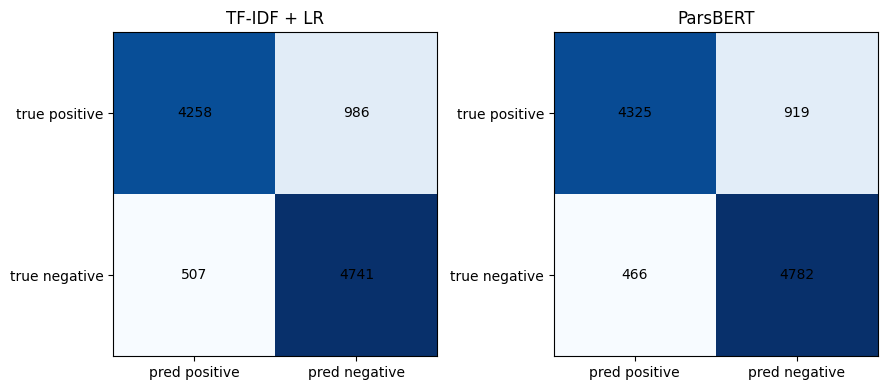

In [33]:
import json, os
import matplotlib.pyplot as plt
from google.colab import files

os.makedirs('/content/cx-radar/reports/figures', exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, p) in zip(axes, [('TF-IDF + LR', p_tfidf), ('ParsBERT', p_bert)]):
    cm = confusion_matrix(y_test, p)
    ax.imshow(cm, cmap='Blues')
    ax.set_title(name)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['pred positive', 'pred negative'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['true positive', 'true negative'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center')
plt.tight_layout()
fig_path = '/content/cx-radar/reports/figures/confusion_matrix.png'
plt.savefig(fig_path, dpi=150)

res = {
  'tfidf_lr': {'acc': float(accuracy_score(y_test, p_tfidf)),
               'macro_f1': float(f1_score(y_test, p_tfidf, average='macro'))},
  'parsbert': {'acc': float(accuracy_score(y_test, p_bert)),
               'macro_f1': float(f1_score(y_test, p_bert, average='macro'))},
  'n_test': int(len(test)),
}
json_path = '/content/cx-radar/reports/results.json'
json.dump(res, open(json_path, 'w'), indent=2)

files.download(fig_path)
files.download(json_path)